# Experiment 4: differential privacy under a fixed 100-epoch overfitting configuration
Compare a freshly trained non-private ACS 2023 MLP with seven DP MLPs at
**epsilon = 0.5, 1, 2, 5, 10, 25, 50**, holding **delta = 1e-6** constant.
Use 100,000 target training records, 48 complete inputs and nominal PINCP >$50,000
labels. ACS 2014 supplies public preprocessing data and 16 tree shadow models.
There is no missing-feature training, masking or reconstruction in this study.

All eight targets use hidden layers **512/256/128**, Adam learning rate **0.001**,
batch size **256**, **no dropout**, **no weight decay**, and **exactly 100 epochs**.
Disable early stopping and best-epoch restoration. Return **epoch 100** regardless
of validation performance; validation histories are monitoring only. The same
predeclared settings apply to every privacy budget. DP may prevent overfitting;
the configuration does not guarantee that every resulting model overfits.

The historical Exp 3 configuration recorded **62.625% target MIA accuracy**,
99.849% target training accuracy and 79.52% target test accuracy. These are
historical context, not new observations or promised results. This notebook
retains the DP experiment's public-only preprocessing and consistent blind-walk
perturbations across shadows and targets. The historical run fitted target
preprocessing on target training rows and used different commuting-field walk
rules for shadows and targets, so this is **not an exact reproduction** of that
62.625% run. No old model or score replaces the fresh non-private control.

Use the same frozen four-feature RF membership attack for every target. The
graphs show equally spaced epsilon categories with a non-private horizontal
reference. Record target utility, generalization gap, MIA accuracy, ROC-AUC and
TPR@1%FPR without selecting a budget using test or membership results.

Noise is calibrated for all 100 epochs using the exact logical-step count and
the conservative Opacus accountant rate, 1 / len(private_loader). The actual
Poisson sampler rate is recorded separately. The full-schedule bound must be
within the requested epsilon before training begins. No privacy budget is reset
between epochs. Compared with 30 epochs, this schedule requires different noise
at the same epsilon, so cross-notebook differences are not an epoch-only effect.

Run experiments only after explicit user approval. No cells have been executed
by creating this notebook. No checkpoints, model files, intermediate predictions
or logs are saved. Final metrics, histories, protocol and PNG/SVG graphs are
exported to a separate directory. The known sklearn parallel warning is hidden;
the three known DP research warnings each appear once. Other warnings and errors
remain visible. Eight 100-epoch runs can take substantially longer than the
early-stopped study.


## Dependencies and fixed study configuration
Use the project virtual environment. If the dependency check below fails, install
`python -m pip install -r requirements.txt` in that environment before running.
Installation is separate from executing this notebook.

Private training uses Opacus per-example gradient clipping and Gaussian noise
with Adam (DP-Adam), Poisson sampling and an RDP accountant. Physical batches
are capped at 32 to limit per-sample-gradient memory; logical batches remain 256.
The existing four paper-inspired attack features, including blind walks, are
retained with consistent numeric perturbations for shadows and targets.


In [1]:
from pathlib import Path
from importlib.util import find_spec
import csv
import gc
import importlib.metadata
import json
import math

missing_dependencies = [name for name in ['opacus', 'matplotlib', 'xgboost'] if find_spec(name) is None]
if missing_dependencies:
    raise ImportError('Missing ' + ', '.join(missing_dependencies)
        + '. Install in this notebook kernel: python -m pip install -r requirements.txt')

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from src.data import split_acs_data, subset_target_training, TARGET
from src.expanded_data import EXPANDED_FEATURES, load_expanded_year, reference_split_config
from src.dp_experiment import (
    prepare_public_preprocessing, train_dp_study_target, plot_budget_accuracy,
)
from src.training import evaluate_model
from src.shadow_models import train_shadow_model, summarize_shadow_models, PAPER_SHADOW_ALGORITHMS
from src.membership_attack import train_membership_classifier, evaluate_attack
from src.paper_attack_features import collect_shadow_paper_features, collect_target_paper_features
from src.notebook_output import CellProgress, quiet_output, suppress_sklearn_parallel_warning

suppress_sklearn_parallel_warning()
torch.set_num_threads(4)
SEED = 42
TARGET_YEAR = 2023
AUXILIARY_YEAR = 2014
TRAIN_SIZE = 100_000
PUBLIC_PREPROCESSING_SIZE = 10_000
EPSILON_BUDGETS = (0.5, 1, 2, 5, 10, 25, 50)
DELTA = 1e-6
assert 0 < DELTA < 1 / TRAIN_SIZE
assert len(EXPANDED_FEATURES) == 48
N_SHADOW_MODELS = 16
SHADOW_RECORDS_PER_CLASS = 2000
SHADOW_ALGORITHMS = PAPER_SHADOW_ALGORITHMS
SPLIT_CONFIG = reference_split_config()
assert SPLIT_CONFIG['seed'] == SEED
TRAIN_CONFIG = dict(hidden_dims=(512, 256, 128), dropout=0.0,
    max_epochs=100, patience=5, min_delta=0.0, batch_size=256,
    max_physical_batch_size=32, learning_rate=1e-3, weight_decay=0.0,
    max_grad_norm=1.0, seed=SEED, device='cpu',
    selection_metric='log_loss', strict_accounting=True,
    early_stopping=False, restore_best=False)
WALK_CONFIG = dict(max_steps=20, repeats=2, categorical_change_probability=0.05,
    batch_size=512, seed=SEED)
EXPANDED_NUMERIC_WALK = {'JWMNP': (2.0, 0, 200), 'JWRIP': (1.0, 1, 10)}
RUN_DIR = Path('artifacts/exp_4_2023_2014_dp_overfitting100_e0p5_1_2_5_10_25_50_d1e6')

for year, filename in [(TARGET_YEAR, 'psam_p06.csv'), (AUXILIARY_YEAR, 'ss14pca.csv')]:
    raw_path = Path('data/raw/folktables') / str(year) / '1-Year' / filename
    with raw_path.open(newline='', encoding='utf-8-sig') as handle:
        columns = set(next(csv.reader(handle)))
    missing_columns = set(EXPANDED_FEATURES + ['PINCP', 'PWGTP']) - columns
    if missing_columns:
        raise ValueError(f'{raw_path}: missing columns {sorted(missing_columns)}')

versions = {name: importlib.metadata.version(name) for name in
    ['torch', 'opacus', 'numpy', 'pandas', 'scikit-learn', 'xgboost', 'matplotlib']}
print('Budgets:', EPSILON_BUDGETS, '| Constant delta:', DELTA)
print('Fixed epochs:', TRAIN_CONFIG['max_epochs'], '| Early stopping: disabled; return final epoch')
print('Complete-feature MIA; four features including blind walks; no reconstruction.')
display(pd.Series(versions, name='package_version'))


Budgets: (0.5, 1, 2, 5, 10, 25, 50) | Constant delta: 1e-06
Fixed epochs: 100 | Early stopping: disabled; return final epoch
Complete-feature MIA; four features including blind walks; no reconstruction.


torch           2.15.0+cpu
opacus               1.6.0
numpy                2.5.4
pandas               3.1.1
scikit-learn         1.9.1
xgboost              3.4.1
matplotlib          3.11.2
Name: package_version, dtype: str

## Public preprocessing and fixed target partitions
Make the same stratified target splits and 100,000-record training subset as
Exp 3. For this research experiment, the fixed 2023 validation partition is
explicitly **public**, outside the protected target training set; it provides
monitoring only and never selects an epoch. Test and MIA nonmember records never select models or thresholds.
The privacy statement is conditional on this fixed partition and concerns
record-level target-training membership, not person-level or survey-selection privacy.

Reserve 10,000 public 2014 rows for preprocessing, disjoint from shadow records.
Learn all imputation/scaling statistics, missing-indicator choices and category
vocabularies on those public rows only, then freeze them for all eight targets.
There is no target-fitted preprocessing. The auxiliary data and validation data
are assumed available independently of the protected training records. Native
category codes remain year-specific; public 2014 vocabulary may not cover all
2023 categories. This limitation applies equally to every target here.


In [2]:
target_source = load_expanded_year(TARGET_YEAR, income_base_year=None)
reference_partitions = split_acs_data(target_source, **SPLIT_CONFIG)
target_partitions = subset_target_training(reference_partitions, train_size=TRAIN_SIZE, seed=SEED)
for name in ['validation', 'test', 'mia_members', 'mia_nonmembers']:
    np.testing.assert_array_equal(target_partitions[name].index, reference_partitions[name].index)
assert len(target_partitions['train']) == TRAIN_SIZE
assert len(target_partitions['mia_members']) == len(target_partitions['mia_nonmembers'])

auxiliary_source = load_expanded_year(AUXILIARY_YEAR, income_base_year=None)
shadow_auxiliary, public_preprocessing = train_test_split(auxiliary_source,
    test_size=PUBLIC_PREPROCESSING_SIZE, stratify=auxiliary_source[TARGET], random_state=SEED)
shadow_auxiliary = shadow_auxiliary.sort_index().copy()
public_preprocessing = public_preprocessing.sort_index().copy()
assert set(shadow_auxiliary.index).isdisjoint(public_preprocessing.index)
assert set(auxiliary_source.index).isdisjoint(target_source.index)
target_preprocessor, target_arrays = prepare_public_preprocessing(public_preprocessing, target_partitions)
partition_counts = {name: len(frame) for name, frame in target_partitions.items()}
display(pd.Series({**partition_counts, 'public_2014_preprocessing': len(public_preprocessing),
    'public_2014_shadow_pool': len(shadow_auxiliary)}, name='records'))
print('Encoded input dimensions shared by all targets:', target_arrays['train']['X'].shape[1])
del target_source, reference_partitions, auxiliary_source
gc.collect()


validation                    10000
test                          10000
mia_nonmembers                10000
train                        100000
mia_members                   10000
public_2014_preprocessing     10000
public_2014_shadow_pool      173941
Name: records, dtype: int64

Encoded input dimensions shared by all targets: 2250


259

## Fit the complete-feature auxiliary attack once
Train 16 public 2014 shadows (6 RF, 5 gradient boosting, 5 XGBoost), keeping their
existing estimator settings and 40/20/40 splits. Each shadow fits its own
training-only preprocessor. Query 2,000 members and 2,000 nonmembers per shadow.
Keep repeated auxiliary IDs in one grouped attack train/validation/test role.
Train one RF membership classifier and freeze its auxiliary-selected thresholds
before evaluating any target. Shadow models are released after feature extraction.

This is a **frozen transfer-attack evaluation** across privacy budgets. The
shadows are not DP MLPs matched to each budget. A weak transferred attack alone
does not establish resistance to an attacker adapted to DP training.


In [3]:
def fit_and_query_shadow(auxiliary, name, algorithm, seed):
    with quiet_output():
        result = train_shadow_model(auxiliary, algorithm, seed=seed, schema='expanded_acs')
        result['attack_data']['shadow_model'] = name
        features, audits = collect_shadow_paper_features({name: result}, auxiliary,
            per_class=SHADOW_RECORDS_PER_CLASS, config=WALK_CONFIG, seed=SEED,
            include_blind_walk=True, numeric_protocol=EXPANDED_NUMERIC_WALK)
    summary = summarize_shadow_models({name: result})
    return features, audits[name], summary

shadow_progress = CellProgress()
shadow_feature_parts, shadow_summary_parts, shadow_query_audits, shadow_seeds = [], [], {}, {}
for index in range(N_SHADOW_MODELS):
    algorithm = SHADOW_ALGORITHMS[index % len(SHADOW_ALGORITHMS)]
    name = f'{algorithm}_{index + 1:02d}'
    shadow_seeds[name] = SEED + 10 * index
    shadow_progress.update(f'Shadow {index + 1}/{N_SHADOW_MODELS}: training/querying {name}')
    features, audit, summary = fit_and_query_shadow(shadow_auxiliary, name, algorithm, shadow_seeds[name])
    shadow_feature_parts.append(features)
    shadow_summary_parts.append(summary)
    shadow_query_audits[name] = audit
    del features, audit, summary
    gc.collect()

shadow_attack_data = pd.concat(shadow_feature_parts, ignore_index=True)
shadow_income_metrics = pd.concat(shadow_summary_parts)
assert len(shadow_attack_data) == N_SHADOW_MODELS * 2 * SHADOW_RECORDS_PER_CLASS
assert shadow_attack_data['shadow_model'].nunique() == N_SHADOW_MODELS
with quiet_output():
    attack_result = train_membership_classifier(shadow_attack_data, seed=SEED,
        algorithm='random_forest', feature_set='paper')
split_ids = {name: set(frame['record_id']) for name, frame in attack_result['splits'].items()}
assert split_ids['train'].isdisjoint(split_ids['validation'] | split_ids['test'])
assert split_ids['validation'].isdisjoint(split_ids['test'])
auxiliary_attack_metrics = pd.DataFrame(attack_result['metrics']).T
shadow_progress.update('All shadows scored; auxiliary attack and thresholds frozen')
display(auxiliary_attack_metrics[['accuracy', 'balanced_accuracy', 'roc_auc', 'tpr_at_1pct_fpr_roc']].round(4))
del shadow_feature_parts, shadow_summary_parts
gc.collect()


,accuracy,balanced_accuracy,roc_auc,tpr_at_1pct_fpr_roc
train,0.6035,0.6040,0.6493,0.0379
validation,0.5168,0.5165,0.5187,0.0132
test,0.5142,0.5130,0.5129,0.0100


120

## Train and evaluate each target at epoch 100
The following helper defines the work; the run cell performs it. Every model
starts from scratch with the same architecture, initialization seed and
unregularized Adam settings. DP adds per-example clipping and Gaussian noise
with Poisson sampling. Opacus sampling/noise generators are independently,
nondeterministically seeded and their seeds are not saved.

Run all 100 epochs and evaluate the final weights. Validation cannot stop a run
or select an earlier epoch. `best_epoch` is a monitoring diagnostic only;
`returned_epoch` must equal 100. Private train metrics and test/MIA measurements
are computed only after training, with no effect on training or thresholds.

Before the first update, calibrate noise using the full private-loader logical
step count and the same conservative rate used by Opacus's accountant. Record
both sampler and accountant rates. After training, assert that all planned
logical steps were executed and the realised accountant epsilon agrees with
the full-schedule bound. Keep delta at 1e-6.

Query the same balanced MIA records with blind walks and the frozen auxiliary
RF attack for every target. This is a transferred attack from non-private tree
shadows, not an attack matched to each DP budget. Final train/test accuracy and
their gap establish whether the intended overfitting actually occurred.


In [4]:
target_progress = CellProgress()

def run_target_condition(epsilon):
    condition = 'non_private' if epsilon is None else f'epsilon_{epsilon:g}'
    target_progress.update(f'{condition}: training from scratch')
    with quiet_output():
        model, history, metadata = train_dp_study_target(
            target_arrays['train']['X'], target_arrays['train']['y'],
            target_arrays['validation']['X'], target_arrays['validation']['y'],
            epsilon=epsilon, delta=DELTA, progress=target_progress.update, **TRAIN_CONFIG)
    assert metadata['epochs_run'] == TRAIN_CONFIG['max_epochs']
    assert metadata['returned_epoch'] == TRAIN_CONFIG['max_epochs']
    assert metadata['actual_optimizer_steps'] == metadata['planned_optimizer_steps']
    if epsilon is not None:
        assert metadata['epsilon_fixed_schedule_bound'] <= epsilon + 1e-6
        assert math.isclose(metadata['epsilon_at_stop_diagnostic'],
            metadata['epsilon_fixed_schedule_bound'], rel_tol=1e-9, abs_tol=1e-9)
    target_progress.update(f'{condition}: evaluating final epoch {metadata["returned_epoch"]}')
    income_metrics = {name: evaluate_model(model, target_arrays[name]['X'], target_arrays[name]['y'])
        for name in ['train', 'validation', 'test']}
    target_progress.update(f'{condition}: querying complete-feature membership attack')
    with quiet_output():
        attack_features, query_audit = collect_target_paper_features(model, target_preprocessor,
            target_partitions, config=WALK_CONFIG, seed=SEED,
            include_blind_walk=True, numeric_protocol=EXPANDED_NUMERIC_WALK)
        mia_metrics, _ = evaluate_attack(attack_result['classifier'], attack_features,
            threshold=attack_result['accuracy_threshold'],
            low_fpr_threshold=attack_result['low_fpr_threshold'])
    assert mia_metrics['records'] == 2 * mia_metrics['members']
    row = dict(condition=condition, private=epsilon is not None,
        epsilon_requested=epsilon, delta=DELTA if epsilon is not None else None,
        epsilon_fixed_schedule_bound=metadata['epsilon_fixed_schedule_bound'],
        epsilon_at_stop_diagnostic=metadata['epsilon_at_stop_diagnostic'],
        noise_multiplier=metadata['noise_multiplier'], epochs_run=metadata['epochs_run'],
        best_epoch=metadata['best_epoch'], returned_epoch=metadata['returned_epoch'],
        planned_optimizer_steps=metadata['planned_optimizer_steps'],
        actual_optimizer_steps=metadata['actual_optimizer_steps'],
        sampler_sample_rate=metadata['sampler_sample_rate'],
        accountant_sample_rate=metadata['accountant_sample_rate'],
        bound_sample_rate=metadata['bound_sample_rate'],
        training_seconds=metadata['training_seconds'],
        target_train_accuracy=income_metrics['train']['accuracy'],
        target_validation_accuracy=income_metrics['validation']['accuracy'],
        target_test_accuracy=income_metrics['test']['accuracy'],
        target_test_roc_auc=income_metrics['test']['roc_auc'],
        target_test_log_loss=income_metrics['test']['log_loss'],
        generalization_gap=income_metrics['train']['accuracy'] - income_metrics['test']['accuracy'],
        mia_accuracy=mia_metrics['accuracy'], mia_balanced_accuracy=mia_metrics['balanced_accuracy'],
        mia_roc_auc=mia_metrics['roc_auc'], mia_tpr_at_1pct_fpr_roc=mia_metrics['tpr_at_1pct_fpr_roc'],
        mia_tpr_at_shadow_threshold=mia_metrics['tpr_at_shadow_threshold'],
        mia_fpr_at_shadow_threshold=mia_metrics['fpr_at_shadow_threshold'])
    metadata.update(income_metrics=income_metrics, membership_metrics=mia_metrics, query_audit=query_audit)
    # Return metrics only: no fitted target, private row scores or model files.
    return row, history, metadata


### Run the eight fixed 100-epoch conditions
This cell trains a fresh non-private control and seven private targets, each
for all 100 epochs. It requires explicit approval to execute. Existing Exp 3
models, predictions and the historical 62.625% score are never substituted.
Report every predeclared budget. Known DP warnings are displayed once per run.


In [5]:
# Reload presentation support only; keep existing data, shadows and attack.
import importlib
import src.notebook_output as notebook_output_module
importlib.reload(notebook_output_module)
from src.notebook_output import compact_dp_warnings

study_rows, training_histories, target_metadata = [], {}, {}
with compact_dp_warnings():
    for epsilon in (None,) + EPSILON_BUDGETS:
        row, history, metadata = run_target_condition(epsilon)
        study_rows.append(row)
        training_histories[row['condition']] = history
        target_metadata[row['condition']] = metadata
        gc.collect()
study_results = pd.DataFrame(study_rows)
assert len(study_results) == 1 + len(EPSILON_BUDGETS)
assert study_results.loc[study_results['private'], 'delta'].eq(DELTA).all()
target_progress.update('All eight conditions completed; final metrics ready')


/home/syedkhaj/MF-MIA-nebula/.venv/lib/python3.12/site-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
/home/syedkhaj/MF-MIA-nebula/.venv/lib/python3.12/site-packages/opacus/accountants/analysis/rdp.py:332: UserWarning: Optimal order is the largest alpha. Please consider expanding the range of alphas to get a tighter privacy bound.
  warnings.warn(
/home/syedkhaj/MF-MIA-nebula/src/dp_experiment.py:219: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
  loss.backward()


## Compare utility, generalization and membership leakage
Accuracies below are fractions; graphs show percentages. The generalization gap
is training accuracy minus test accuracy. A small gap with poor test accuracy can
indicate underfitting, so both are reported. Ordinary MIA accuracy uses one
auxiliary-validation-selected threshold, frozen across targets. ROC-AUC and
TPR@1%FPR supplement accuracy so threshold transfer is visible.


In [6]:
display(study_results.set_index('condition')[[
    'epsilon_requested', 'epsilon_fixed_schedule_bound', 'epsilon_at_stop_diagnostic',
    'delta', 'epochs_run', 'returned_epoch', 'target_train_accuracy', 'target_test_accuracy',
    'generalization_gap', 'mia_accuracy', 'mia_roc_auc', 'mia_tpr_at_1pct_fpr_roc'
]].round(6))

display(study_results.set_index('condition')[[
    'sampler_sample_rate', 'accountant_sample_rate', 'bound_sample_rate',
    'noise_multiplier', 'planned_optimizer_steps', 'actual_optimizer_steps'
]])


,epsilon_requested,epsilon_fixed_schedule_bound,epsilon_at_stop_diagnostic,delta,epochs_run,returned_epoch,target_train_accuracy,target_test_accuracy,generalization_gap,mia_accuracy,mia_roc_auc,mia_tpr_at_1pct_fpr_roc
condition,,,,,,,,,,,,
non_private,NaN,NaN,NaN,NaN,100,100,0.99841,0.7854,0.21301,0.57955,0.609531,0.0016
epsilon_0.5,0.5,0.491537,0.491537,0.000001,100,100,0.79005,0.7899,0.00015,0.50575,0.506917,0.0136
epsilon_1,1.0,0.993826,0.993826,0.000001,100,100,0.80238,0.7999,0.00248,0.49980,0.499695,0.0106
epsilon_2,2.0,1.995987,1.995987,0.000001,100,100,0.80953,0.7990,0.01053,0.50160,0.503518,0.0093
epsilon_5,5.0,4.993633,4.993633,0.000001,100,100,0.81782,0.8077,0.01012,0.50100,0.503262,0.0114
epsilon_10,10.0,9.991104,9.991104,0.000001,100,100,0.82109,0.8113,0.00979,0.50210,0.503825,0.0094
epsilon_25,25.0,24.997075,24.997075,0.000001,100,100,0.82628,0.8120,0.01428,0.50795,0.512068,0.0092
epsilon_50,50.0,49.992751,49.992751,0.000001,100,100,0.82960,0.8135,0.01610,0.50405,0.508562,0.0099


,sampler_sample_rate,accountant_sample_rate,bound_sample_rate,noise_multiplier,planned_optimizer_steps,actual_optimizer_steps
condition,,,,,,
non_private,NaN,NaN,NaN,NaN,39100,39100
epsilon_0.5,0.002558,0.002564,0.002564,4.531250,39000,39000
epsilon_1,0.002558,0.002564,0.002564,2.421875,39000,39000
epsilon_2,0.002558,0.002564,0.002564,1.396484,39000,39000
epsilon_5,0.002558,0.002564,0.002564,0.827026,39000,39000
epsilon_10,0.002558,0.002564,0.002564,0.646973,39000,39000
epsilon_25,0.002558,0.002564,0.002564,0.505562,39000,39000
epsilon_50,0.002558,0.002564,0.002564,0.428677,39000,39000


## Graph 1: target model accuracy versus privacy budget
Use held-out **income-prediction test accuracy**. Epsilon labels are categories
with equal spacing, not numeric coordinates. The dashed line is the matched
non-private control. Budget labels describe requested maximum-schedule budgets;
actual accountant values and final epochs are available in the result table.


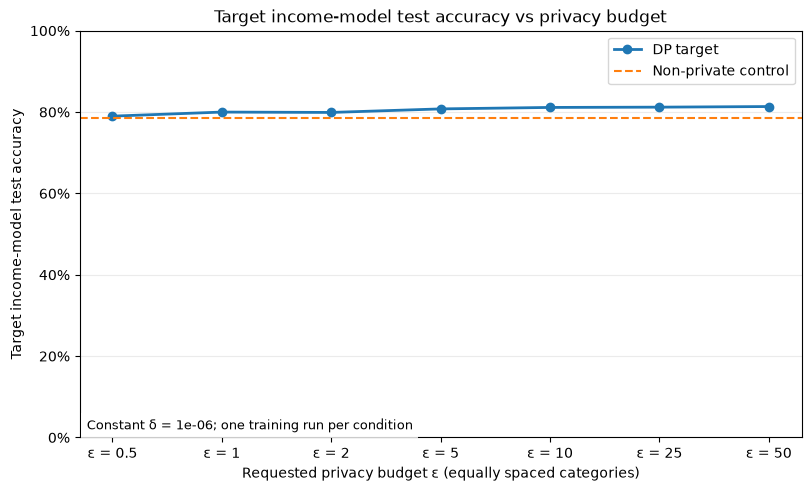

In [7]:
figure, axes = plot_budget_accuracy(study_results, EPSILON_BUDGETS,
    metric='target_test_accuracy', output_dir=RUN_DIR, delta=DELTA)
display(figure)
plt.close(figure)


## Graph 2: membership inference accuracy versus privacy budget
Use complete-feature **target MIA accuracy**, with the same categorical epsilon
axis. The non-private control and 50% chance level are horizontal references.
Chance is 50% because members and nonmembers are equally represented. Neither
curve is forced to be monotonic. One run per condition does not support error
bars or a claim that a near-chance attack proves privacy.


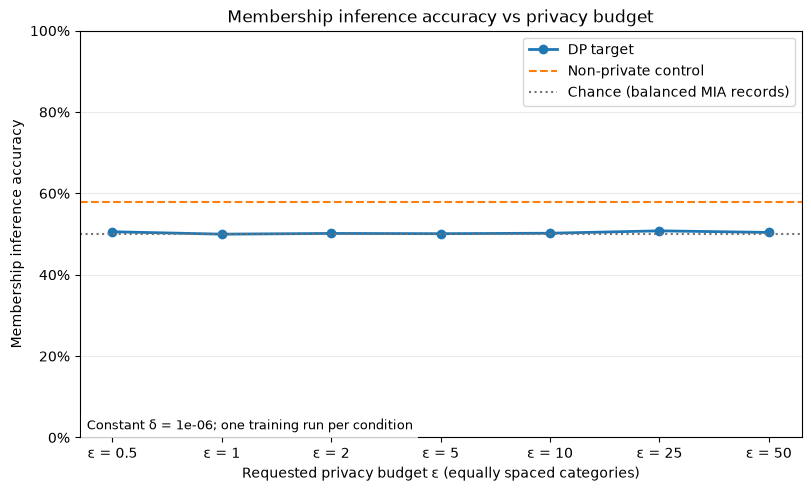

In [8]:
figure, axes = plot_budget_accuracy(study_results, EPSILON_BUDGETS,
    metric='mia_accuracy', output_dir=RUN_DIR, delta=DELTA)
display(figure)
plt.close(figure)


## Save results and interpret the comparison
Save final CSV metrics, all 100 monitoring epochs, protocol and both graphs to
the separate overfitting-study directory. No models, row-level predictions,
checkpoints or logs are saved. Private evaluation statistics in these research
outputs are not DP-sanitized releases.

The epsilon/delta claim concerns each individual target model with its fixed
public preprocessor, conditional on the fixed research split. Releasing several
models trained on the same records requires composition; the non-private
control has no DP guarantee. secure_mode=False is a research setting.

This experiment evaluates the final epoch after a fixed schedule. There is no
adaptive stopping or best-epoch selection. The full-schedule bound and final
accountant diagnostic use the same conservative rate and should agree.

The training settings are intended to expose a larger non-private train/test
gap, but observed gaps and leakage must be measured. The historical 62.625%
MIA score came from a different preprocessing and shadow-walk protocol and is
not a guaranteed baseline here. A near-chance tree-shadow transfer attack does
not establish robustness to stronger attacks. There is one run per condition;
the early-stopped study and this study also differ in regularization, learning
rate and DP noise calibration, so comparing them is not an epoch-only ablation.


In [9]:
def json_value(value):
    if isinstance(value, dict):
        return {str(key): json_value(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_value(item) for item in value]
    if isinstance(value, np.generic):
        return json_value(value.item())
    if isinstance(value, float) and not math.isfinite(value):
        return str(value)
    return value

RUN_DIR.mkdir(parents=True, exist_ok=True)
study_results.to_csv(RUN_DIR / 'dp_target_and_mia_metrics.csv', index=False)
auxiliary_attack_metrics.to_csv(RUN_DIR / 'auxiliary_attack_metrics.csv')
shadow_income_metrics.to_csv(RUN_DIR / 'shadow_income_metrics.csv')
for condition, history in training_histories.items():
    pd.DataFrame(history).to_csv(RUN_DIR / f'{condition}_public_validation_history.csv', index=False)
protocol = dict(study_variant='Fixed 100-epoch unregularized DP study',
    historical_reference=dict(target_mia_accuracy=0.62625,
        source='artifacts/exp_3_2023_2014_100000_nominal_paper_algorithms/summary.json',
        role='Historical context only; not a new result or exact reproduction'),
    accounting_calibration='Exact private-loader steps; conservative Opacus accountant rate',
    execution_status='complete', target_year=TARGET_YEAR, auxiliary_year=AUXILIARY_YEAR,
    epsilon_budgets=EPSILON_BUDGETS, delta=DELTA, train_size=TRAIN_SIZE,
    feature_count=len(EXPANDED_FEATURES), features=EXPANDED_FEATURES,
    label='nominal PINCP > 50000', split_config=SPLIT_CONFIG, target_partition_sizes=partition_counts,
    public_preprocessing_records=PUBLIC_PREPROCESSING_SIZE,
    preprocessing_scope='Fixed public 2014 subset, disjoint from shadow pool; shared by all targets',
    public_validation='Fixed 2023 validation split outside protected training records',
    training_config=TRAIN_CONFIG, target_results=target_metadata,
    privacy_scope='Individual target model; record-level DP conditional on fixed partition/public data',
    privacy_bound='Fixed full 100-epoch schedule; final accountant epsilon agrees with bound',
    secure_mode=False, research_outputs_are_dp_releases=False,
    multiple_models='Per-model bounds; joint release requires composition; control is non-private',
    n_shadow_models=N_SHADOW_MODELS, shadow_algorithms=SHADOW_ALGORITHMS, shadow_seeds=shadow_seeds,
    records_per_class_per_shadow=SHADOW_RECORDS_PER_CLASS,
    attack='Frozen complete-feature RF transfer attack; non-DP tree shadows',
    attack_features=list(attack_result['classifier'].feature_names_in_), include_blind_walk=True,
    walk_config=WALK_CONFIG, extra_numeric_protocol=EXPANDED_NUMERIC_WALK,
    walk_scope='Consistent extra numeric protocol for shadows and targets',
    shadow_query_audits=shadow_query_audits, auxiliary_attack_metrics=attack_result['metrics'],
    accuracy_threshold=attack_result['accuracy_threshold'], low_fpr_threshold=attack_result['low_fpr_threshold'],
    plots='Equally spaced categorical requested epsilon labels; non-private horizontal reference',
    versions=versions, checkpoints_enabled=False, logging_enabled=False,
    missing_feature_experiments=False, repeated_seed_confirmation=False)
_ = (RUN_DIR / 'protocol.json').write_text(json.dumps(json_value(protocol), indent=2, allow_nan=False), encoding='utf-8')
print('Final metrics:', RUN_DIR / 'dp_target_and_mia_metrics.csv')
print('Graphs: target_accuracy_vs_epsilon and mia_accuracy_vs_epsilon (PNG and SVG)')


Final metrics: artifacts/exp_4_2023_2014_dp_overfitting100_e0p5_1_2_5_10_25_50_d1e6/dp_target_and_mia_metrics.csv
Graphs: target_accuracy_vs_epsilon and mia_accuracy_vs_epsilon (PNG and SVG)


Implementation references:
[Opacus PrivacyEngine](https://opacus.ai/api/privacy_engine.html),
[BatchMemoryManager](https://opacus.ai/api/batch_memory_manager.html),
[DPDataLoader](https://opacus.ai/api/data_loader.html),
[Opacus FAQ](https://opacus.ai/docs/faq).
